In [1]:
using Statistics
using Revise, Plots
using BifurcationKit
using LinearAlgebra

In [2]:
# Parameters for the CAMKII activation (ionotrop plasticity)
CaMKT = 16.6  # fixed by experiments see Graupner-Brunel 2007
# phosphorylation
k5 = 0.1  # fixed by experiments see Graupner-Brunel 2007
k6 = 6
k7 = 6  # same values as Graupner-Brunel 2007
# dephosporylation
k12 = 6000
KM = 0.4  # same values as Graupner-Brunel 2007
# Calmodulin
CaMT = 0.07342
Ka1 = 0.1
Ka2 = 0.025
Ka3 = 0.32
Ka4 = 0.40  # fixed by experiments see Graupner-Brunel 2007
# PP1 / I1
PP10 = 0.2  # same values as Graupner-Brunel 2007
k11 = 500
km11 = 0.1
I10 = 1  # same values as Graupner-Brunel 2007

1

In [3]:
function compute_phos_CamK2(y)
    return y[1] + 2*sum(y[2:4]) + 3*sum(y[5:8]) + 4*sum(y[9:11]) + 5*y[12] + 6*y[13]
end


compute_phos_CamK2 (generic function with 1 method)

In [4]:
function mat_CamK2(y, Ca, PP1)
    rr = sum(y[1:13])
    B0 = 2 * CaMKT - rr

    phossum = y[1] +
              2 * sum(y[2:4]) +
              3 * sum(y[5:8]) +
              4 * sum(y[9:11]) +
              5 * y[12] +
              6 * y[13]

    k10 = k12 * PP1 / (KM + phossum)
    CaM = CaMT / (1 + Ka4 / Ca + Ka3 * Ka4 / Ca^2 + Ka2 * Ka3 * Ka4 / Ca^3 + Ka1 * Ka2 * Ka3 * Ka4 / Ca^4)
    gamma = CaM / (k5 + CaM)

    g2k6 = k6 * gamma^2
    gk7  = k7 * gamma

    mat = [
        -4*g2k6 - gk7 - k10   2*k10   2*k10   2*k10   0   0   0   0   0   0   0   0   0   6*g2k6*B0;
        gk7 + g2k6            -3*g2k6 - gk7 - 2*k10   0   0   2*k10   k10   k10   0   0   0   0   0   0   0;
        2*g2k6                0   -2*gk7 - 2*g2k6 - 2*k10   0   k10   k10   k10   3*k10   0   0   0   0   0   0;
        g2k6                  0   0   -2*gk7 - 2*g2k6 - 2*k10   0   k10   k10   0   0   0   0   0   0   0;
        0   gk7 + g2k6        gk7   0   -gk7 - 2*g2k6 - 3*k10   0   0   0   2*k10   k10   0   0   0   0;
        0   g2k6              g2k6   2*gk7   0   -g2k6 - 2*gk7 - 3*k10   0   0   k10   k10   2*k10   0   0   0;
        0   g2k6              gk7   2*g2k6   0   0   -g2k6 - 2*gk7 - 3*k10   0   k10   k10   2*k10   0   0   0;
        0   0                 g2k6   0   0   0   0   -3*gk7 - 3*k10   0   k10   0   0   0   0;
        0   0                 0   0   gk7 + g2k6   gk7   gk7   0   -g2k6 - gk7 - 4*k10   0   0   2*k10   0   0;
        0   0                 0   0   g2k6   g2k6   gk7   3*gk7   0   -2*gk7 - 4*k10   0   2*k10   0   0;
        0   0                 0   0   0   gk7   g2k6   0   0   0   -2*gk7 - 4*k10   k10   0   0;
        0   0                 0   0   0   0   0   0   gk7 + g2k6   2*gk7   2*gk7   -gk7 - 5*k10   6*k10   0;
        0   0                 0   0   0   0   0   0   0   0   0   gk7   -6*k10   0
    ]

    mat
end


mat_CamK2 (generic function with 1 method)

In [5]:
# p is a NamedTuple or struct with fields Ca and PP1
function F!(du, u, p)
    y13 = @view u[1:13]
    mat = mat_CamK2(y13, p.Ca, p.PP1)

    tmp_y = zeros(eltype(u), 14)
    tmp_y[1:13] .= y13
    tmp_y[14] = 1.0

    du .= mat * tmp_y
end


F! (generic function with 1 method)

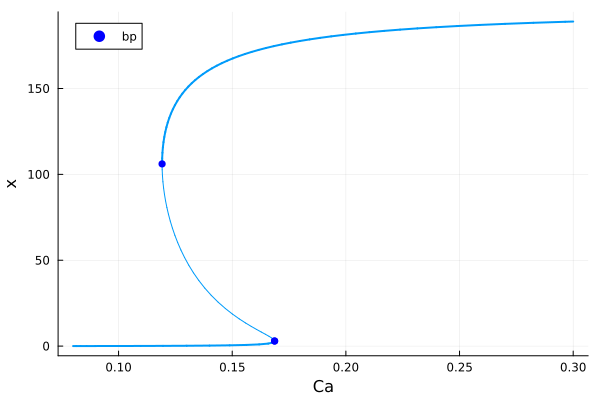

In [6]:
# Bifurcation Problem
par_tm = (Ca = 0.08, PP1 = 15e-4)
u0 = fill(0.003, 13)

prob = ODEBifProblem(F!, u0, par_tm, (@optic _.Ca);
	record_from_solution = (z, p; k...) -> compute_phos_CamK2(z),
	)

opts_br = ContinuationPar(
    p_min = 0.05, p_max = 0.3,
    #newton_options = newton_opts,
    nev = 20, ds = 0.001
)

# continuation of equilibria
br = continuation(prob, PALC(tangent=Bordered()), opts_br; normC = norminf)

scene = plot(br, plotfold=false, markersize=4, legend=:topleft)#, vars = (:z1, :z3)

In [7]:
using BifurcationKit

# example initial parameter set
p0 = (Ca = 0.2, PP1 = 8e-3)#, ...)   # put your other constants here

u0 = fill(0.01, 13)
# continuation in Ca
probCa = BifurcationProblem(F!, u0, p0, (@optic _.Ca))
optsCa = ContinuationPar(
    p_min = 1e-6, p_max = 1.5,
    ds = 1e-3, dsmin = 1e-6, dsmax = 0.05,
    max_steps = 5000
)
brCa = continuation(probCa, PALC(), optsCa)

# continuation in PP1
probPP1 = BifurcationProblem(F, u0, p0, (@optic _.PP1))
optsPP1 = ContinuationPar(
    p_min = 8e-3, p_max = 35e-3,
    ds = 1e-4, dsmin = 1e-6, dsmax = 1e-3,
    max_steps = 5000
)
brPP1 = continuation(probPP1, PALC(), optsPP1)


UndefVarError: UndefVarError: `F` not defined in `Main`
Suggestion: check for spelling errors or missing imports.

In [8]:
#FOR ALL PPI1
using BifurcationKit
using Plots

PP1_values = [0.001, 0.002, 0.003, 0.004, 0.005]

u0 = fill(0.003, 13)

opts_br = ContinuationPar(
    p_min = 0.05,
    p_max = 0.5,
    nev = 20,
    ds = 0.001,
    detect_bifurcation = 3
)



ContinuationPar{Float64, DefaultLS, DefaultEig{typeof(real)}}
  dsmin: Float64 0.0001
  dsmax: Float64 0.1
  ds: Float64 0.001
  a: Float64 0.5
  p_min: Float64 0.05
  p_max: Float64 0.5
  max_steps: Int64 400
  newton_options: NewtonPar{Float64, DefaultLS, DefaultEig{typeof(real)}}
  η: Float64 150.0
  save_to_file: Bool false
  save_sol_every_step: Int64 1
  nev: Int64 20
  save_eig_every_step: Int64 1
  save_eigenvectors: Bool true
  plot_every_step: Int64 10
  tol_stability: Float64 1.0e-10
  detect_fold: Bool true
  detect_bifurcation: Int64 3
  dsmin_bisection: Float64 1.0e-16
  n_inversion: Int64 2
  max_bisection_steps: Int64 25
  tol_bisection_eigenvalue: Float64 1.0e-16
  detect_event: Int64 0
  tol_param_bisection_event: Float64 1.0e-16
  detect_loop: Bool false


In [9]:
branches = Dict()

for PP1 in PP1_values

    println("Calcul pour PP1 = $PP1")

    par_tm = (
        Ca = 0.08,
        PP1 = PP1
    )

    prob = ODEBifProblem(
        F!,
        u0,
        par_tm,
        (@optic _.Ca);
        record_from_solution =
            (z, p; k...) -> compute_phos_CamK2(z)
    )

    br = continuation(
        prob,
        PALC(tangent = Bordered()),
        opts_br;
        normC = norminf
    )

    branches[PP1] = br

end

Calcul pour PP1 = 0.001
Calcul pour PP1 = 0.002
Calcul pour PP1 = 0.003
Calcul pour PP1 = 0.004
Calcul pour PP1 = 0.005


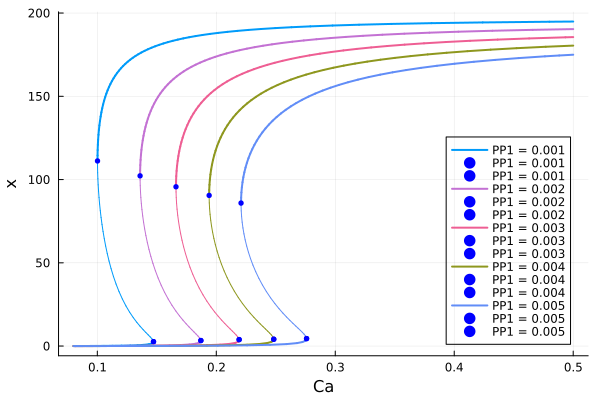

In [13]:
plt = plot(
    xlabel = "Ca",
    ylabel = "Phosphorylation de CaMKII",
    legend = :bottomright,
    background_color_legend = :transparent,
)

for PP1 in PP1_values

    br = branches[PP1]

    plot!(
        plt,
        br;
        label = "PP1 = $PP1",
        plotfold = false,
    )

end

display(plt)